# Классификация музыкальных жанров: сравнение MLP, CNN и EfficientNet

О чём этот проект

В этом проекте сравниваются три подхода к классификации музыкальных жанров по спектрограммам:

- простая полносвязная сеть (MLP) — уже реализованная ранее в процессе обучения,

- собственная свёрточная нейронная сеть (CNN),

- предобученная модель (EfficientNet B0).

# Цель проекта
Построить и сравнить модели классификации спектрограмм и сделать выводы о том, какой подход работает лучше и почему.

# Общие условия
- Среда: Google Colab (GPU).

- Фреймворк: PyTorch.

- Датасет: спектрограммы музыкальных жанров.

- Метрика: accuracy.

In [1]:
# Импортируем необходимые библиотеки

import os

import kagglehub

import time
import random
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset

import torchvision
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA доступна:", torch.cuda.is_available())


PyTorch: 2.11.0+cu128
torchvision: 0.26.0+cu128
CUDA доступна: True


In [2]:
# Фиксация случайности для воспроизводимости и выбор устройства (CPU/GPU)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# выбираем устройство
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f"Используем устройство: {device}")

Используем устройство: cuda


## 1. Загрузка датасета GTZAN

Используем тот же датасет, что и в практике MLP — `andradaolteanu/gtzan-dataset-music-genre-classification`. Качаем через `kagglehub` (нужен настроенный `~/.kaggle/kaggle.json`).

Если `kagglehub` не сработает (нет Kaggle API token), можно вручную скачать датасет с [Kaggle](https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification) и подменить переменную `path` на путь к локальной папке.

Из всего датасета нам нужна только папка `images_original/` со спектрограммами в виде PNG. Сырые `.wav` (`genres_original/`) и табличные признаки (`features_*.csv`) для этого проекта не нужны.

In [3]:
# скачивает (или использует уже скачанный) датасет в ~/.cache/kagglehub/...

path = kagglehub.dataset_download("andradaolteanu/gtzan-dataset-music-genre-classification")
print("Датасет:", path)

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
Датасет: /kaggle/input/gtzan-dataset-music-genre-classification


In [4]:
# универсальный поиск пути к спектрограммам — структура папок у kagglehub
# иногда отличается (бывает Data/ внутри, бывает без)
possible_image_paths = [
    os.path.join(path, "Data", "images_original"),
    os.path.join(path, "images_original"),
]

image_path = None
for p in possible_image_paths:
    if os.path.exists(p):
        image_path = p
        break

if image_path is None:
    raise RuntimeError(f"Не нашёл images_original в {path}")

print("Папка со спектрограммами:", image_path)

Папка со спектрограммами: /kaggle/input/gtzan-dataset-music-genre-classification/Data/images_original


## Подготовка данных

Определяем данные и разбиваем их на train/val/test - 70/15/15, как в учебном примере.

In [5]:
class_names = sorted([d for d in os.listdir(image_path) if os.path.isdir(os.path.join(image_path, d))])
print(f"Найдены жанры: {class_names}")

Найдены жанры: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


In [6]:
# Удаляем битый файл
broken_file = os.path.join(image_path, 'jazz', 'jazz00054.png')
if os.path.exists(broken_file):
    print("Удаляем поврежденный файл:", broken_file)
    os.remove(broken_file)

In [7]:
image_paths = []
image_labels = []

for class_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(image_path, class_name)
    image_files = sorted(glob.glob(os.path.join(class_dir, "*.png")))

    for img_path in image_files:
        # загружаем изображение
        img = Image.open(img_path).convert('RGB')
        image_paths.append(img)
        image_labels.append(class_idx)

print(f"Всего изображений: {len(image_paths)}")
print(f"Всего таргетов: {len(image_labels)}")


n_samples = len(image_paths)
all_indices = np.arange(n_samples)

# Сначала отделяем train (70%) от временной выборки (30%)
train_idx, temp_idx = train_test_split(
    all_indices,
    train_size=0.70,
    random_state=SEED,
    stratify=image_labels
)

# Вычисляем пропорцию для разделения временной выборки пополам (15% и 15% от общего числа)
temp_labels = [image_labels[i] for i in temp_idx]

val_idx, test_idx = train_test_split(
    temp_idx,
    train_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print(f'Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}')

Всего изображений: 999
Всего таргетов: 999
Train: 699, Val: 150, Test: 150


## Кастомный `Dataset`

Делаю  `Dataset`для удобства подменять `transform` под каждую модель (128×128 для CNN, 224×224 + аугментация для EfficientNet).

In [8]:
class SpectrogramDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = self.paths[idx].convert('RGB')
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

## Функция обучения

Общая функция для CNN и EfficientNet — отличаются только оптимизаторами и числом эпох.

In [9]:
MODELS_DIR = Path('models')
MODELS_DIR.mkdir(exist_ok=True)

def evaluate(model, loader, device):
    model.eval()
    correct, total = 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            preds = outputs.argmax(dim=1)
            total += y.size(0)
            correct += (preds == y).sum().item()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    return correct / total, all_preds, all_labels


def train_model(model, train_loader, val_loader, *, epochs, optimizer, device, model_name):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    best_val_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                outputs = model(x)
                loss = criterion(outputs, y)
                val_loss += loss.item()
                preds = outputs.argmax(dim=1)
                total += y.size(0)
                correct += (preds == y).sum().item()
        val_loss /= len(val_loader)
        val_acc = correct / total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), MODELS_DIR / f'best_{model_name}.pth')

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f'{model_name} | Эпоха {epoch + 1}/{epochs} | '
                f'train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}'
            )

    model.load_state_dict(torch.load(MODELS_DIR / f'best_{model_name}.pth', map_location=device, weights_only=True))
    return model, history, best_val_acc


## Задание 1. Свёрточная сеть

Своя свёрточная нейронная сеть по следующей логике:

- Последовательно добавлены три свёрточных слоя с числом каналов: 32 → 64 → 128.

- После каждого свёрточного слоя применены:
    - функцию активации ReLU,
    - слой MaxPooling.

- Далее добавлена полносвязная часть:

    - слой на 256 нейронов с активацией ReLU,
    - слой Dropout с вероятностью 0,3 (для борьбы с переобучением),
    - выходной слой на десять классов.

- Параметры обучения:

    - входные изображения размером 128 × 128,
    - оптимизатор AdamW,
    - обучение в течение 50 эпох.

In [10]:
class GenreCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # 128x128 -> после 3 MaxPool: 16x16
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

cnn_dataset = SpectrogramDataset(image_paths, image_labels, transform=cnn_transform)
batch_size = 32
# num_workers=0 обязателен в Jupyter: воркеры не видят классы, объявленные в ноутбуке
num_workers = 0

cnn_train_loader = DataLoader(Subset(cnn_dataset, train_idx), batch_size=batch_size, shuffle=True, num_workers=num_workers)
cnn_val_loader = DataLoader(Subset(cnn_dataset, val_idx), batch_size=batch_size, shuffle=False, num_workers=num_workers)
cnn_test_loader = DataLoader(Subset(cnn_dataset, test_idx), batch_size=batch_size, shuffle=False, num_workers=num_workers)

cnn_model = GenreCNN(num_classes=len(class_names))
print(cnn_model)
print(f'Параметров: {sum(p.numel() for p in cnn_model.parameters()):,}')

GenreCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Параметров: 8,484,682


In [11]:
cnn_optimizer = optim.AdamW(cnn_model.parameters(), lr=1e-3, weight_decay=0.01)
cnn_model, cnn_history, cnn_best_val = train_model(
    cnn_model,
    cnn_train_loader,
    cnn_val_loader,
    epochs=50,
    optimizer=cnn_optimizer,
    device=device,
    model_name='cnn',
)
print(f'Лучшая val accuracy (CNN): {cnn_best_val:.4f}')

cnn | Эпоха 1/50 | train_loss=2.3190 | val_loss=2.1838 | val_acc=0.2000
cnn | Эпоха 10/50 | train_loss=1.0989 | val_loss=1.3116 | val_acc=0.5267
cnn | Эпоха 20/50 | train_loss=0.3143 | val_loss=1.5781 | val_acc=0.5533
cnn | Эпоха 30/50 | train_loss=0.1320 | val_loss=2.1091 | val_acc=0.5400
cnn | Эпоха 40/50 | train_loss=0.0464 | val_loss=2.5933 | val_acc=0.5933
cnn | Эпоха 50/50 | train_loss=0.0445 | val_loss=2.8159 | val_acc=0.5733
Лучшая val accuracy (CNN): 0.6133


In [12]:
cnn_test_acc, cnn_preds, cnn_labels = evaluate(cnn_model, cnn_test_loader, device)
print(f'CNN test accuracy: {cnn_test_acc:.4f} ({cnn_test_acc * 100:.2f}%)')

CNN test accuracy: 0.5600 (56.00%)


## Задание 2. Transfer Learning — EfficientNet B0

- Сделана модель на основе предобученной EfficientNet B0:

    - Загружена модель с весами, обученными на ImageNet.
    - Заморожены все слои (чтобы их веса не обновлялись при обучении).
    - Заменен последний слой (классификатор) на новый — для десяти классов.

- Добавлена аугментация данных:

    - случайное отражение (RandomHorizontalFlip),
    - случайный поворот (RandomRotation).

- Параметры обучения:

    - размер входных изображений: 224 × 224,
    - оптимизатор: Adam,
    - обучение: 30 эпох.

In [13]:
effnet_weights = EfficientNet_B0_Weights.IMAGENET1K_V1
effnet_preset = effnet_weights.transforms()
effnet_mean, effnet_std = effnet_preset.mean, effnet_preset.std

# train: с аугментацией (по условию задания — Flip + Rotation).
# Угол поворота специально небольшой: спектрограмма — это график "частота × время",
# и сильный поворот ломает её структуру (оси разные по смыслу, в отличие от фото).
# 5° сохраняет регуляризацию, но не разрушает информацию.

effnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(mean=effnet_mean, std=effnet_std),
])

effnet_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=effnet_mean, std=effnet_std),
])

effnet_train_dataset = SpectrogramDataset(image_paths, image_labels, transform=effnet_train_transform)
effnet_eval_dataset = SpectrogramDataset(image_paths, image_labels, transform=effnet_eval_transform)

effnet_train_loader = DataLoader(Subset(effnet_train_dataset, train_idx), batch_size=16, shuffle=True, num_workers=num_workers)
effnet_val_loader = DataLoader(Subset(effnet_eval_dataset, val_idx), batch_size=16, shuffle=False, num_workers=num_workers)
effnet_test_loader = DataLoader(Subset(effnet_eval_dataset, test_idx), batch_size=16, shuffle=False, num_workers=num_workers)

effnet_model = efficientnet_b0(weights=effnet_weights)
for param in effnet_model.parameters():
    param.requires_grad = False

in_features = effnet_model.classifier[1].in_features
effnet_model.classifier[1] = nn.Linear(in_features, len(class_names))

trainable = sum(p.numel() for p in effnet_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in effnet_model.parameters())
print(f'EfficientNet B0: обучаемых параметров {trainable:,} из {total:,}')

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 88.6MB/s]


EfficientNet B0: обучаемых параметров 12,810 из 4,020,358


In [14]:
effnet_optimizer = optim.Adam(filter(lambda p: p.requires_grad, effnet_model.parameters()), lr=1e-3)
effnet_model, effnet_history, effnet_best_val = train_model(
    effnet_model,
    effnet_train_loader,
    effnet_val_loader,
    epochs=30,
    optimizer=effnet_optimizer,
    device=device,
    model_name='effnet',
)
print(f'Лучшая val accuracy (EfficientNet): {effnet_best_val:.4f}')

effnet | Эпоха 1/30 | train_loss=2.0380 | val_loss=1.9270 | val_acc=0.4133
effnet | Эпоха 10/30 | train_loss=1.1325 | val_loss=1.3742 | val_acc=0.5533
effnet | Эпоха 20/30 | train_loss=1.0150 | val_loss=1.3239 | val_acc=0.5600
effnet | Эпоха 30/30 | train_loss=0.9132 | val_loss=1.2750 | val_acc=0.6200
Лучшая val accuracy (EfficientNet): 0.6200


In [15]:
effnet_test_acc, effnet_preds, effnet_labels = evaluate(effnet_model, effnet_test_loader, device)
print(f'EfficientNet test accuracy: {effnet_test_acc:.4f} ({effnet_test_acc * 100:.2f}%)')

EfficientNet test accuracy: 0.6333 (63.33%)


## Задание 3. Сравнение результатов

In [16]:
mlp_baseline = 0.3046

results = pd.DataFrame({
    'Модель': [
        'MLP (reference.ipynb, спектрограммы 64×64)',
        'Свёрточная сеть (CNN)',
        'EfficientNet B0 (transfer learning)',
    ],
    'Точность': [
        f'{mlp_baseline * 100:.2f}%',
        f'{cnn_test_acc * 100:.2f}%',
        f'{effnet_test_acc * 100:.2f}%',
    ],
})
display(results)

,Модель,Точность
0,"MLP (reference.ipynb, спектрограммы 64×64)",30.46%
1,Свёрточная сеть (CNN),56.00%
2,EfficientNet B0 (transfer learning),63.33%


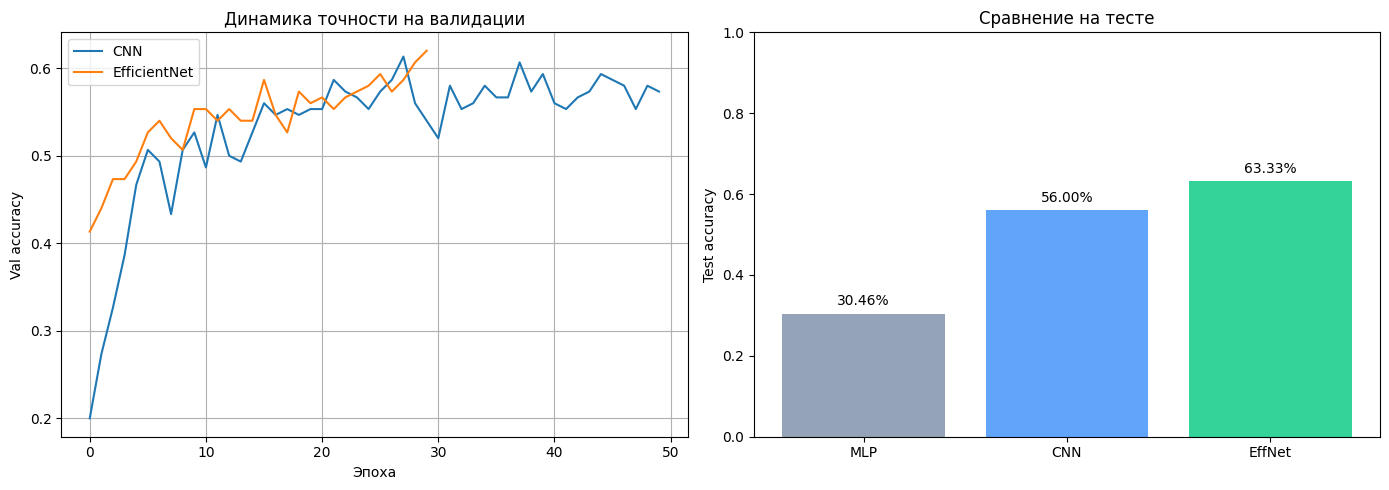

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(cnn_history['val_acc'], label='CNN')
axes[0].plot(effnet_history['val_acc'], label='EfficientNet')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Val accuracy')
axes[0].set_title('Динамика точности на валидации')
axes[0].legend()
axes[0].grid(True)

models = ['MLP', 'CNN', 'EffNet']
accs = [mlp_baseline, cnn_test_acc, effnet_test_acc]
bars = axes[1].bar(models, accs, color=['#94a3b8', '#60a5fa', '#34d399'])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('Test accuracy')
axes[1].set_title('Сравнение на тесте')
for bar, acc in zip(bars, accs):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f'{acc:.2%}', ha='center')

plt.tight_layout()
plt.show()

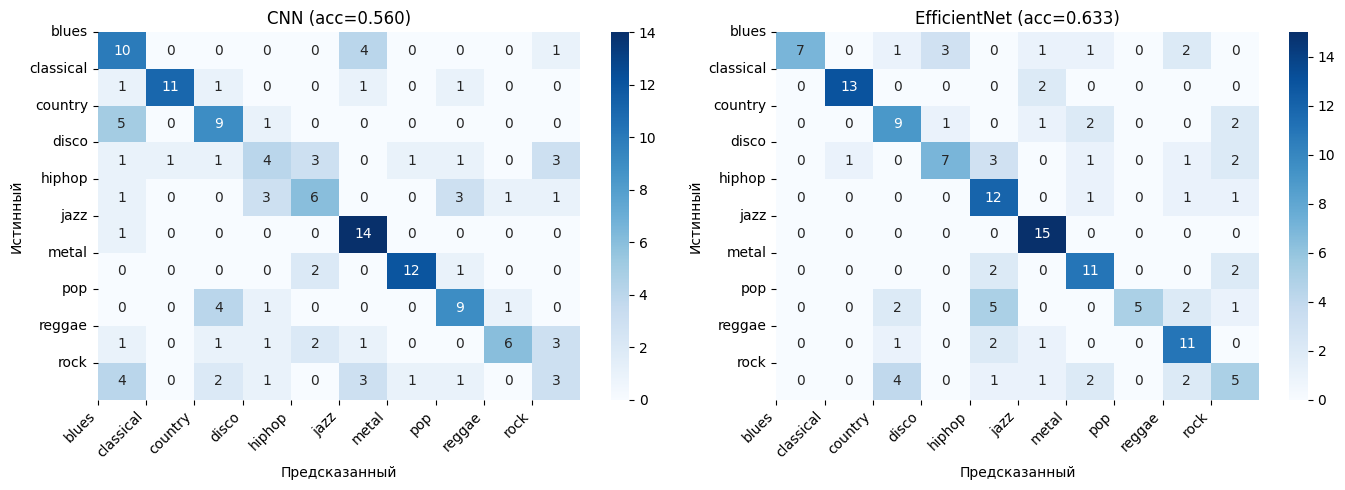

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, preds, labels, title in [
    (axes[0], cnn_preds, cnn_labels, f'CNN (acc={cnn_test_acc:.3f})'),
    (axes[1], effnet_preds, effnet_labels, f'EfficientNet (acc={effnet_test_acc:.3f})'),
]:
    cm = confusion_matrix(labels, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Предсказанный')
    ax.set_ylabel('Истинный')
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticklabels(class_names, rotation=0)

plt.tight_layout()
plt.show()

Выводы

1. MLP (30.46%) — худший результат, ожидаемо, сеть разворачивает спектрограмму в вектор и не использует пространственную структуру и не видит локальные зависимости пикселей.

2. CNN (56.00%) — существенный рост относительно MLP. CNN извлекает локальные паттерны на спектрограмме.

3. EfficientNet B0 (63.33%) — лучший результат. Предобучение на ImageNet даёт богатые фильтры низкого уровня, аугментация снижает переобучение на маленьком датасете (1000 изображений).

MLP из практики показал 30.46%, потому что полносвязная сеть воспринимает спектрограмму как набор независимых пикселей и не учитывает их соседство — для неё одинаковая локальная структура в разных частях картинки выглядит как разные признаки. Собственная CNN достигла 56.00% за счёт свёрточных фильтров, которые скользящим окном пробегают по всей картинке с общими весами и выделяют локальные паттерны спектрограммы (горизонтальные обертоны, удары перкуссии, ритмические повторы). Несколько свёрточных слоёв подряд расширяют «поле обзора», и модель учит иерархические признаки — от перепадов яркости до жанровых паттернов. EfficientNet B0 показала 63.33% за счёт того, что её "базовые слои" уже обучены на миллионах картинок ImageNet и содержат готовые детекторы краёв и простых текстур. Нам остаётся обучить только новую выходной слой на 10 классов. Таким образом, при переходе от MLP к CNN и далее к transfer learning важно не общее число параметров, а архитектура и качество представлений: CNN бьёт MLP за счёт учёта пространственной структуры, а EfficientNet — за счёт переиспользования предобученных универсальных признаков.